# Notebook 11 — Seed Stability and Architecture Benchmark

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | At one tuned training setting, how do the shortlisted architectures compare when each is trained with five seeds, and which of them are within noise of the best? |
| **Purpose of this notebook** | Train every candidate with five new seeds, describe the resulting distributions, benchmark the shortlisted architectures against one another and against the frozen Track A model under the decision rule, and record the comparisons that the final selection uses. |
| **Inputs** | `results/09_candidates.json`: eight candidates with their roles and training settings (see Section 1). |
| **What is varied** | The seed, and the architecture across the benchmark candidates. |
| **What is held fixed** | For every benchmark candidate: the tuned training setting (learning rate 3e-4, weight decay 0.01, batch 256, warm-up 0.05), T300 encoding, data, splits, evaluation view, epoch budget and early stopping. |
| **Test data** | Not used. The test split stays locked. |
| **Outputs** | `results/11_seed_runs.csv`, `results/11_seed_summary.csv`, `results/11_pairwise.csv`, `results/11_best_versus_candidates.csv`, `results/11_depth_comparisons.csv`, `results/11_stability_report.json`, figures in `figures/`. |

Authored by: Alisha Shaikh (PICT, Pune)

In [ ]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every notebook of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import math
import copy
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"

OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
RUNS_DIR = OPT_DIR / "runs"
RESULTS_DIR = OPT_DIR / "results"
FIGURES_DIR = OPT_DIR / "figures"
CONFIG_DIR = OPT_DIR / "config"
MANIFEST_DIR = OPT_DIR / "manifests"
LOG_DIR = OPT_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Track A project (read-only):", EXISTING_DIR)
print("Experiment outputs:", OPT_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Track A project (read-only): /content/drive/MyDrive/soccer_mi/track_a
Experiment outputs: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib

import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    TRACK_A_FROZEN = json.load(handle)

ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]

BASE_LAYERS = TRACK_A_FROZEN["model"]["n_layers"]
BASE_HEADS = TRACK_A_FROZEN["model"]["n_heads"]
BASE_D_MODEL = TRACK_A_FROZEN["model"]["d_model"]
BASE_D_FF = TRACK_A_FROZEN["model"]["d_ff"]
BASE_CONTEXT = TRACK_A_FROZEN["context_length"]
BASE_LR = TRACK_A_FROZEN["training"]["learning_rate"]
BASE_WD = TRACK_A_FROZEN["training"]["weight_decay"]
EPOCH_BUDGET = TRACK_A_FROZEN["training"]["max_epochs"]

print("Events:", len(events), "| device:", DEVICE)
print("Track A reference configuration:",
      f"L{BASE_LAYERS} H{BASE_HEADS} d_model {BASE_D_MODEL} d_ff {BASE_D_FF} K{BASE_CONTEXT}",
      f"| lr {BASE_LR:g} wd {BASE_WD:g} | epoch budget {EPOCH_BUDGET}")

Events: 658905 | device: cuda
Track A reference configuration: L2 H2 d_model 128 d_ff 512 K16 | lr 0.0003 wd 0.1 | epoch budget 30


In [ ]:
# ----------------
# Helper functions
# ----------------

SHORT_NAME = {"batch_size": "bs", "warmup_fraction": "wu"}


def transformer_config(seed, n_layers, n_heads, context_length, d_model=None, d_ff=None,
                       learning_rate=None, weight_decay=None, max_epochs=None):
    """Build a run configuration in exactly the format used by the Track A notebooks."""
    model = {"n_layers": n_layers, "n_heads": n_heads,
             "d_model": BASE_D_MODEL if d_model is None else d_model,
             "d_ff": BASE_D_FF if d_ff is None else d_ff}
    training_settings = {"learning_rate": BASE_LR if learning_rate is None else learning_rate,
                         "weight_decay": BASE_WD if weight_decay is None else weight_decay,
                         "max_epochs": EPOCH_BUDGET if max_epochs is None else max_epochs}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": context_length, "stride": STRIDE, "seed": seed,
            "model": model, "training": training_settings}


def architecture_label(config):
    """Readable architecture name, e.g. L4-H2-K16-D128-F512."""
    model = config["model"]
    return (f"L{model['n_layers']}-H{model['n_heads']}-K{config['context_length']}"
            f"-D{model['d_model']}-F{model['d_ff']}")


def variant_tag(training_settings):
    """Sub-folder for training settings that training.run_name_for() does not encode.

    run_name_for() encodes the learning rate, weight decay, architecture, context length and
    seed, but not the batch size or the warm-up fraction. Two runs that differ only in those
    two settings would otherwise be written to the same folder and the second would silently
    reload the first. Any setting that differs from the Track A default therefore becomes part
    of the folder name.
    """
    parts = []
    for key in ["batch_size", "warmup_fraction"]:
        if key in training_settings and training_settings[key] != training.DEFAULT_TRAINING[key]:
            parts.append(f"{SHORT_NAME[key]}{training_settings[key]:g}")
    return "_".join(parts) if parts else "base"


_BUNDLES = {}


def bundle_for(context_length):
    """Encoded data and evaluation views for one context length (built once, then reused)."""
    if context_length not in _BUNDLES:
        _BUNDLES[context_length] = training.prepare_data(
            events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, context_length, STRIDE, DEVICE, RUN_MODE)
    return _BUNDLES[context_length]


def parameter_count(config):
    """Total parameters of a configuration, without training it."""
    model = training.build_model(config, bundle_for(config["context_length"])["vocabulary_sizes"])
    return model_module.count_parameters(model)["total"]


def run_one(config, extra_training=None, keep_every_epoch=False, verbose=True):
    """Train one configuration (or reload it if its folder already holds a finished run).

    Returns (run_dir, final_results). Nothing outside RUNS_DIR is written.
    """
    config = copy.deepcopy(config)
    if extra_training:
        config["training"].update(extra_training)
    runs_root = RUNS_DIR / variant_tag(config["training"])
    runs_root.mkdir(parents=True, exist_ok=True)
    result = training.train_run(config, bundle_for(config["context_length"]), runs_root,
                                MANIFEST_PATH, keep_every_epoch=keep_every_epoch, verbose=verbose)
    return runs_root / training.run_name_for(config), result


def result_row(config, run_dir, result, group=""):
    """One flat record per run, holding every quantity the later notebooks need."""
    val = result["val_metrics"]
    training_settings = result["training_settings"]
    return {
        "group": group,
        "architecture": architecture_label(config),
        "n_layers": config["model"]["n_layers"],
        "n_heads": config["model"]["n_heads"],
        "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
        "d_model": config["model"]["d_model"],
        "d_ff": config["model"]["d_ff"],
        "context_length": config["context_length"],
        "learning_rate": training_settings["learning_rate"],
        "weight_decay": training_settings["weight_decay"],
        "batch_size": training_settings["batch_size"],
        "warmup_fraction": training_settings["warmup_fraction"],
        "seed": config["seed"],
        "parameters": result["parameter_counts"]["total"],
        "trainable_parameters": result["parameter_counts"].get("trainable", result["parameter_counts"]["total"]),
        "val_nll": val["nll"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
        "val_top3": val["top3_accuracy"],
        "val_top5": val["top5_accuracy"],
        "val_ece": val["ece"],
        "train_nll": result["train_nll"],
        "best_epoch": result["best_epoch"],
        "epochs_run": result["epochs_run"],
        "stopped_early": result["stopped_early"],
        "diverged": result["diverged"],
        "runtime_seconds": result["runtime_seconds"],
        "run_dir": str(run_dir),
        "run_name": result["run_name"],
    }


def append_results(rows, csv_path):
    """Append run records to a CSV, keeping one row per run name and variant folder."""
    table = pd.DataFrame(rows)
    if Path(csv_path).exists():
        table = pd.concat([pd.read_csv(csv_path), table], ignore_index=True)
    table = table.drop_duplicates(subset=["run_dir"], keep="last").reset_index(drop=True)
    table.to_csv(csv_path, index=False)
    return table


def seed_level_to_config_level(table):
    """Average the seed-level records of each configuration into one row per configuration."""
    keys = ["group", "architecture", "n_layers", "n_heads", "d_head", "d_model", "d_ff",
            "context_length", "learning_rate", "weight_decay", "batch_size", "warmup_fraction",
            "parameters"]
    summary = table.groupby(keys, as_index=False, sort=False).agg(
        n_seeds=("seed", "count"),
        val_nll=("val_nll", "mean"),
        val_nll_sd=("val_nll", "std"),
        val_accuracy=("val_accuracy", "mean"),
        val_accuracy_sd=("val_accuracy", "std"),
        val_macro_f1=("val_macro_f1", "mean"),
        val_top3=("val_top3", "mean"),
        val_top5=("val_top5", "mean"),
        val_ece=("val_ece", "mean"),
        train_nll=("train_nll", "mean"),
        best_epoch=("best_epoch", "mean"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
    return summary.sort_values("val_nll").reset_index(drop=True)


def run_dirs_for(table, **conditions):
    """All run directories in a results table that match the given column values."""
    selected = table
    for column, value in conditions.items():
        selected = selected[selected[column] == value]
    return [Path(path) for path in selected["run_dir"]]


print("Helper functions defined.")

Helper functions defined.


## 1. Why this notebook exists

The capacity sweep and the training-hyperparameter search ranked configurations with one or two seeds each. Rankings from so few runs can be produced by the seed alone: two initialisations of the same configuration give different validation NLLs, and when the gap between two configurations is no larger than that variation, the ordering carries no information. Every ordering so far is therefore provisional. Here each candidate gets five seeds, enough for the decision rule to be applied.

**Candidates** (read from `results/09_candidates.json`):

| Role | Candidates | Training setting | Eligible for selection? |
|---|---|---|---|
| **benchmark** | the six shortlisted architectures, all K = 16, d_model 128, d_ff 512: 8L_2H, 6L_1H, 6L_2H, 6L_8H, 4L_2H, 2L_2H | tuned: learning rate 3e-4, weight decay 0.01 | yes |
| **reference** | the frozen Track A configuration (2L_2H_K16) | Track A: learning rate 3e-4, weight decay 0.1 | no |
| **tuning check** | 6L_2H_K16 | Track A: weight decay 0.1 | no |

Benchmark candidates differ in architecture only, so comparisons among them are architecture comparisons at one training setting. The reference differs from the benchmark candidates in training setting as well as architecture. The tuning check differs from the benchmark 6L_2H_K16 only in weight decay.

**Seeds.** Five seeds, 10 to 14. They are disjoint from the screening seeds (0 and 1) used in the capacity sweep and hyperparameter search, from the development seeds 0–2 used in Track A, and from the seeds 100–104 reserved for final training. Keeping them separate means the final training is a new set of runs, not a re-reading of runs already inspected during selection.

**Why five.** Five is the number of seeds Track A used for final training. It is enough to describe a distribution and see whether two sets of runs overlap, at one run per seed per candidate. It is a **PROVISIONAL** budget choice.

In [ ]:
CANDIDATES_JSON = RESULTS_DIR / "09_candidates.json"
if not CANDIDATES_JSON.exists():
    raise RuntimeError("BLOCKED: results/09_candidates.json is missing. Run notebook 09 first.")
with open(CANDIDATES_JSON) as handle:
    candidate_record = json.load(handle)
CANDIDATES = candidate_record["candidates"]

STABILITY_SEEDS = [10, 11, 12, 13, 14]
SEED_RUNS_CSV = RESULTS_DIR / "11_seed_runs.csv"
SEED_SUMMARY_CSV = RESULTS_DIR / "11_seed_summary.csv"
PAIRWISE_CSV = RESULTS_DIR / "11_pairwise.csv"
BEST_VERSUS_CSV = RESULTS_DIR / "11_best_versus_candidates.csv"
DEPTH_CSV = RESULTS_DIR / "11_depth_comparisons.csv"
STABILITY_REPORT_JSON = RESULTS_DIR / "11_stability_report.json"

print("Tuned training setting (notebook 09):", json.dumps({key: candidate_record["selected_training"][key]
      for key in ["learning_rate", "weight_decay", "batch_size", "warmup_fraction"]}))
print(f"Candidates: {len(CANDIDATES)} | seeds: {STABILITY_SEEDS} | runs: {len(CANDIDATES) * len(STABILITY_SEEDS)}")
pd.DataFrame(CANDIDATES)[["name", "role", "architecture", "parameters", "learning_rate", "weight_decay", "source"]]

Tuned training setting (notebook 09): {"learning_rate": 0.0003, "weight_decay": 0.01, "batch_size": 256, "warmup_fraction": 0.05}
Candidates: 8 | seeds: [10, 11, 12, 13, 14] | runs: 40


,name,role,architecture,parameters,learning_rate,weight_decay,source
0,6L_2H_K16,benchmark,L6-H2-K16-D128-F512,1307663,0.0003,0.01,"notebook 08 shortlist, trained with the notebo..."
1,8L_2H_K16,benchmark,L8-H2-K16-D128-F512,1704207,0.0003,0.01,"notebook 08 shortlist, trained with the notebo..."
2,6L_1H_K16,benchmark,L6-H1-K16-D128-F512,1307663,0.0003,0.01,"notebook 08 shortlist, trained with the notebo..."
3,4L_2H_K16,benchmark,L4-H2-K16-D128-F512,911119,0.0003,0.01,"notebook 08 shortlist, trained with the notebo..."
4,6L_8H_K16,benchmark,L6-H8-K16-D128-F512,1307663,0.0003,0.01,"notebook 08 shortlist, trained with the notebo..."
5,2L_2H_K16,benchmark,L2-H2-K16-D128-F512,514575,0.0003,0.01,"notebook 08 shortlist, trained with the notebo..."
6,Track A reference,reference,L2-H2-K16-D128-F512,514575,0.0003,0.10,frozen Track A configuration
7,6L_2H_K16 (Track A hyperparameters),tuning check,L6-H2-K16-D128-F512,1307663,0.0003,0.10,tuning check: the fine-search architecture at ...


## 2. Training the candidates across seeds

Each of the 8 candidates is trained with seeds 10–14 (40 runs) under the unchanged training procedure.

In [ ]:
def config_for_candidate(candidate, seed):
    return transformer_config(seed, candidate["n_layers"], candidate["n_heads"],
                              candidate["context_length"], d_model=candidate["d_model"],
                              d_ff=candidate["d_ff"], learning_rate=candidate["learning_rate"],
                              weight_decay=candidate["weight_decay"])


seed_rows = []
candidate_run_dirs = {}
for candidate in CANDIDATES:
    print(f"\n{candidate['name']} — {candidate['architecture']} "
          f"(lr {candidate['learning_rate']:.4g}, wd {candidate['weight_decay']:g}, {candidate['role']})")
    directories = []
    for seed in STABILITY_SEEDS:
        config = config_for_candidate(candidate, seed)
        extra = {}
        if candidate["batch_size"] != training.DEFAULT_TRAINING["batch_size"]:
            extra["batch_size"] = candidate["batch_size"]
        if candidate["warmup_fraction"] != training.DEFAULT_TRAINING["warmup_fraction"]:
            extra["warmup_fraction"] = candidate["warmup_fraction"]
        run_dir, result = run_one(config, extra_training=extra or None, verbose=False)
        row = result_row(config, run_dir, result, group="stability")
        row["candidate"] = candidate["name"]
        row["role"] = candidate["role"]
        seed_rows.append(row)
        directories.append(run_dir)
        print(f"  seed {seed}: val NLL {row['val_nll']:.4f} | acc {row['val_accuracy']:.4f} "
              f"| macro-F1 {row['val_macro_f1']:.4f} | ECE {row['val_ece']:.4f} "
              f"| best epoch {row['best_epoch']}")
    candidate_run_dirs[candidate["name"]] = directories

seed_table = pd.DataFrame(seed_rows)
if seed_table["diverged"].any():
    raise RuntimeError("BLOCKED: a stability run diverged: "
                       f"{list(seed_table[seed_table['diverged']]['run_name'])}. Inspect it before comparing.")
for name, subset in seed_table.groupby("candidate"):
    assert sorted(subset["seed"]) == STABILITY_SEEDS, f"{name}: missing seed results"
seed_table.to_csv(SEED_RUNS_CSV, index=False)
print(f"\n{len(seed_table)} runs recorded in {SEED_RUNS_CSV.name}")


6L_2H_K16 — L6-H2-K16-D128-F512 (lr 0.0003, wd 0.01, benchmark)
  seed 10: val NLL 0.9044 | acc 0.6228 | macro-F1 0.5636 | ECE 0.0171 | best epoch 7
  seed 11: val NLL 0.9026 | acc 0.6238 | macro-F1 0.5585 | ECE 0.0207 | best epoch 6
  seed 12: val NLL 0.9028 | acc 0.6232 | macro-F1 0.5593 | ECE 0.0213 | best epoch 8
  seed 13: val NLL 0.9027 | acc 0.6200 | macro-F1 0.5577 | ECE 0.0085 | best epoch 6
  seed 14: val NLL 0.9001 | acc 0.6218 | macro-F1 0.5614 | ECE 0.0145 | best epoch 7

8L_2H_K16 — L8-H2-K16-D128-F512 (lr 0.0003, wd 0.01, benchmark)
  seed 10: val NLL 0.9007 | acc 0.6230 | macro-F1 0.5624 | ECE 0.0264 | best epoch 10
  seed 11: val NLL 0.9009 | acc 0.6227 | macro-F1 0.5633 | ECE 0.0106 | best epoch 7
  seed 12: val NLL 0.9005 | acc 0.6227 | macro-F1 0.5642 | ECE 0.0209 | best epoch 8
  seed 13: val NLL 0.9017 | acc 0.6208 | macro-F1 0.5597 | ECE 0.0122 | best epoch 6
  seed 14: val NLL 0.9011 | acc 0.6199 | macro-F1 0.5596 | ECE 0.0133 | best epoch 7

6L_1H_K16 — L6-H1-

## 3. Distribution of each metric across seeds

For each candidate the table reports the mean and SD of validation NLL and accuracy; the mean of macro-F1, top-3, top-5 and ECE; the range of best epochs; and the minimum, maximum and range of validation NLL over the five seeds. With five values the range is easier to interpret than the SD, so both are given.

The columns `val_nll_ci_low` and `val_nll_ci_high` are a t-interval for the mean of the five seed values. They describe training noise.

**RESULT.** Mean validation NLL (seed SD) in ascending order: 8L_2H_K16 0.9010 (0.0005), 6L_1H_K16 0.9021 (0.0015), 6L_2H_K16 0.9025 (0.0015), tuning check 0.9031 (0.0010), 4L_2H_K16 0.9036 (0.0017), 6L_8H_K16 0.9043 (0.0017), Track A reference 0.9069 (0.0018), 2L_2H_K16 0.9070 (0.0020).

**OBSERVATION.** The 8-layer model has both the lowest mean and the smallest seed spread (range 0.0012 against 0.0027–0.0054 for the others). The Track A reference (weight decay 0.1) and the same architecture at the tuned setting (2L_2H_K16, weight decay 0.01) are almost identical (0.9069 and 0.9070).

In [ ]:
from scipy import stats

stability_rows = []
for candidate in CANDIDATES:
    subset = seed_table[seed_table["candidate"] == candidate["name"]]
    n_seeds = len(subset)
    half_width = stats.t.ppf(0.975, n_seeds - 1) * subset["val_nll"].std(ddof=1) / np.sqrt(n_seeds)
    stability_rows.append({
        "candidate": candidate["name"],
        "role": candidate["role"],
        "architecture": candidate["architecture"],
        "n_layers": candidate["n_layers"],
        "n_heads": candidate["n_heads"],
        "context_length": candidate["context_length"],
        "d_model": candidate["d_model"],
        "d_ff": candidate["d_ff"],
        "parameters": candidate["parameters"],
        "learning_rate": candidate["learning_rate"],
        "weight_decay": candidate["weight_decay"],
        "batch_size": candidate["batch_size"],
        "warmup_fraction": candidate["warmup_fraction"],
        "n_seeds": n_seeds,
        "val_nll_mean": subset["val_nll"].mean(),
        "val_nll_sd": subset["val_nll"].std(ddof=1),
        "val_nll_ci_low": subset["val_nll"].mean() - half_width,
        "val_nll_ci_high": subset["val_nll"].mean() + half_width,
        "val_nll_min": subset["val_nll"].min(),
        "val_nll_max": subset["val_nll"].max(),
        "val_nll_range": subset["val_nll"].max() - subset["val_nll"].min(),
        "val_accuracy_mean": subset["val_accuracy"].mean(),
        "val_accuracy_sd": subset["val_accuracy"].std(ddof=1),
        "val_macro_f1_mean": subset["val_macro_f1"].mean(),
        "val_macro_f1_sd": subset["val_macro_f1"].std(ddof=1),
        "val_top3_mean": subset["val_top3"].mean(),
        "val_top5_mean": subset["val_top5"].mean(),
        "val_ece_mean": subset["val_ece"].mean(),
        "val_ece_sd": subset["val_ece"].std(ddof=1),
        "best_epoch_min": int(subset["best_epoch"].min()),
        "best_epoch_max": int(subset["best_epoch"].max()),
        "runtime_minutes_mean": subset["runtime_seconds"].mean() / 60,
    })
stability_table = pd.DataFrame(stability_rows).sort_values("val_nll_mean").reset_index(drop=True)
stability_table.to_csv(SEED_SUMMARY_CSV, index=False)
stability_table.round(4)

,candidate,role,architecture,n_layers,n_heads,context_length,d_model,d_ff,parameters,learning_rate,weight_decay,batch_size,warmup_fraction,n_seeds,val_nll_mean,val_nll_sd,val_nll_ci_low,val_nll_ci_high,val_nll_min,val_nll_max,val_nll_range,val_accuracy_mean,val_accuracy_sd,val_macro_f1_mean,val_macro_f1_sd,val_top3_mean,val_top5_mean,val_ece_mean,val_ece_sd,best_epoch_min,best_epoch_max,runtime_minutes_mean
0,8L_2H_K16,benchmark,L8-H2-K16-D128-F512,8,2,16,128,512,1704207,0.0003,0.01,256,0.05,5,0.9010,0.0005,0.9004,0.9016,0.9005,0.9017,0.0012,0.6218,0.0014,0.5618,0.0021,0.9482,0.9946,0.0167,0.0067,6,10,3.1525
1,6L_1H_K16,benchmark,L6-H1-K16-D128-F512,6,1,16,128,512,1307663,0.0003,0.01,256,0.05,5,0.9021,0.0015,0.9003,0.9039,0.8997,0.9037,0.0040,0.6218,0.0011,0.5577,0.0047,0.9483,0.9944,0.0170,0.0053,6,8,2.3176
2,6L_2H_K16,benchmark,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.0003,0.01,256,0.05,5,0.9025,0.0015,0.9006,0.9044,0.9001,0.9044,0.0043,0.6223,0.0015,0.5601,0.0024,0.9485,0.9945,0.0164,0.0052,6,8,2.3095
3,6L_2H_K16 (Track A hyperparameters),tuning check,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.0003,0.10,256,0.05,5,0.9031,0.0010,0.9019,0.9044,0.9018,0.9045,0.0027,0.6222,0.0014,0.5593,0.0081,0.9480,0.9944,0.0230,0.0069,8,10,2.5798
4,4L_2H_K16,benchmark,L4-H2-K16-D128-F512,4,2,16,128,512,911119,0.0003,0.01,256,0.05,5,0.9036,0.0017,0.9015,0.9057,0.9016,0.9055,0.0039,0.6216,0.0015,0.5590,0.0033,0.9482,0.9944,0.0196,0.0045,7,9,1.8225
5,6L_8H_K16,benchmark,L6-H8-K16-D128-F512,6,8,16,128,512,1307663,0.0003,0.01,256,0.05,5,0.9043,0.0017,0.9023,0.9064,0.9032,0.9072,0.0040,0.6215,0.0010,0.5600,0.0069,0.9480,0.9944,0.0199,0.0072,6,8,2.3401
6,Track A reference,reference,L2-H2-K16-D128-F512,2,2,16,128,512,514575,0.0003,0.10,256,0.05,5,0.9069,0.0018,0.9047,0.9092,0.9052,0.9100,0.0048,0.6208,0.0021,0.5583,0.0029,0.9474,0.9941,0.0161,0.0048,6,8,1.0567
7,2L_2H_K16,benchmark,L2-H2-K16-D128-F512,2,2,16,128,512,514575,0.0003,0.01,256,0.05,5,0.9070,0.0020,0.9045,0.9094,0.9049,0.9103,0.0054,0.6208,0.0017,0.5583,0.0029,0.9474,0.9941,0.0164,0.0045,6,8,1.0525


/tmp/ipykernel_2248/3352857541.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(nll_groups, labels=order, widths=0.5)
/tmp/ipykernel_2248/3352857541.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(accuracy_groups, labels=order, widths=0.5)


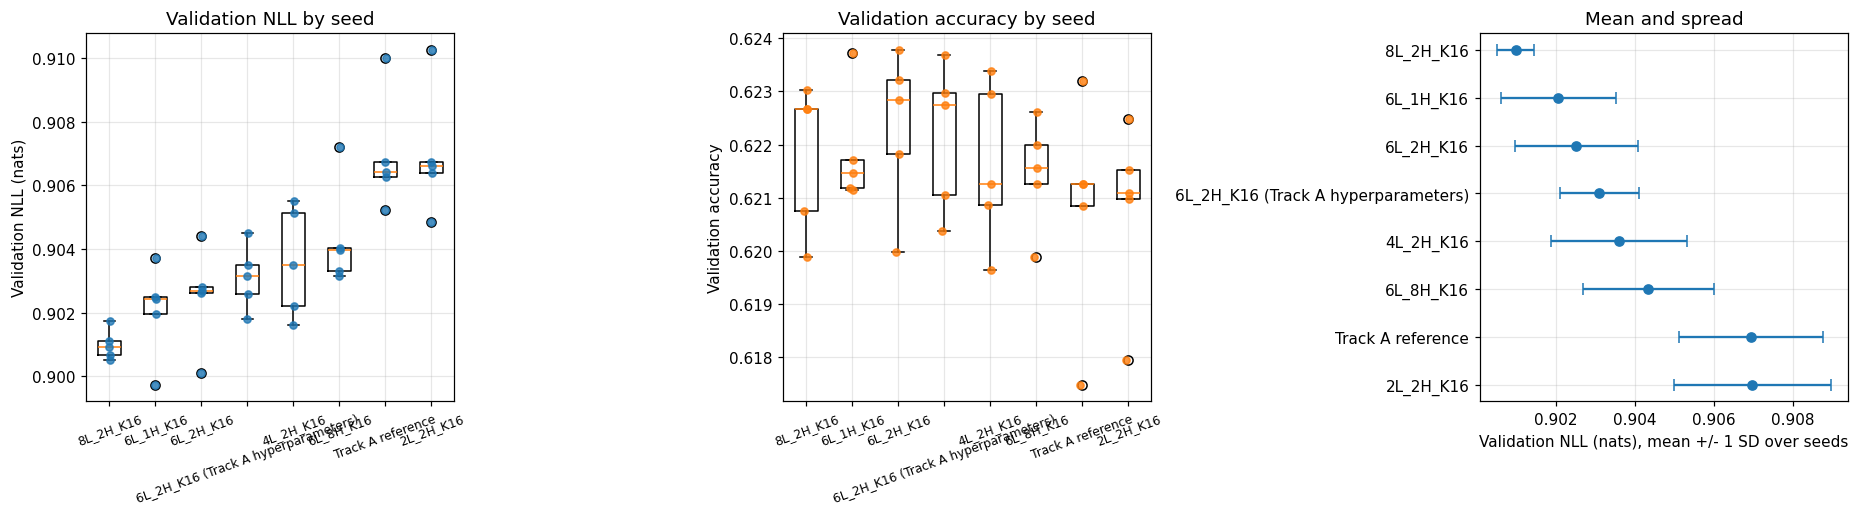

In [ ]:
order = list(stability_table["candidate"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

nll_groups = [seed_table[seed_table["candidate"] == name]["val_nll"].to_numpy() for name in order]
accuracy_groups = [seed_table[seed_table["candidate"] == name]["val_accuracy"].to_numpy() for name in order]

axes[0].boxplot(nll_groups, labels=order, widths=0.5)
for position, values in enumerate(nll_groups, start=1):
    axes[0].scatter(np.full(len(values), position) + np.random.default_rng(0).normal(0, 0.03, len(values)),
                    values, s=22, alpha=0.8, color="tab:blue", zorder=3)
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("Validation NLL by seed")

axes[1].boxplot(accuracy_groups, labels=order, widths=0.5)
for position, values in enumerate(accuracy_groups, start=1):
    axes[1].scatter(np.full(len(values), position) + np.random.default_rng(1).normal(0, 0.03, len(values)),
                    values, s=22, alpha=0.8, color="tab:orange", zorder=3)
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Validation accuracy by seed")

axes[2].errorbar(stability_table["val_nll_mean"], range(len(stability_table)),
                 xerr=stability_table["val_nll_sd"], fmt="o", capsize=4)
axes[2].set_yticks(range(len(stability_table)))
axes[2].set_yticklabels(stability_table["candidate"])
axes[2].invert_yaxis()
axes[2].set_xlabel("Validation NLL (nats), mean +/- 1 SD over seeds")
axes[2].set_title("Mean and spread")

for ax in axes[:2]:
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_seed_distributions.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Left and centre: one box per candidate over its five seeds, for validation NLL and validation accuracy, with each seed shown as a point. Right: mean validation NLL per candidate with ± one seed SD.

**What it shows.** The two 2-layer candidates (reference and 2L_2H_K16) sit clearly above the others in NLL. Among the 4-, 6- and 8-layer candidates the boxes overlap: the whole range of 6L_1H_K16 (0.8997–0.9037) contains the whole range of 8L_2H_K16 (0.9005–0.9017). Accuracy separates the candidates even less.

**How to read it.** Overlapping boxes belong to candidates this experiment cannot separate, whatever their means. Boxes clear of each other indicate a difference that persists across initialisations. The formal version of this judgement is the pairwise comparison in the next section. Individual points matter as much as boxes: one outlying seed widens a box for a candidate that is otherwise consistent (for example seed 13 of the Track A reference, 0.9100).

## 4. Pairwise comparison under the decision rule

**Decision rule ("better beyond noise").** Candidate A is better than candidate B beyond noise only when **both** hold:

1. **Data noise:** the 95% match-level bootstrap interval of the mean per-event NLL difference (A − B), computed on per-event validation NLL averaged over seeds, lies entirely below zero. Whole matches are resampled because events within a match are not independent.
2. **Training noise:** every seed of A has a lower validation NLL than every seed of B (complete seed separation).

This is the rule under which the Track A model was selected. Neither part introduces a threshold on the size of a difference. All 28 pairs of the 8 candidates are compared; every comparison uses the same 68,003 validation events.

In [ ]:
pairwise_rows = []
names = list(stability_table["candidate"])
for position_a, name_a in enumerate(names):
    for name_b in names[position_a + 1:]:
        comparison = analysis.compare_conditions(candidate_run_dirs[name_a], candidate_run_dirs[name_b],
                                                 targets, match_ids)
        pairwise_rows.append({
            "candidate_a": name_a, "candidate_b": name_b,
            "mean_nll_a": comparison["nll_a_mean"], "mean_nll_b": comparison["nll_b_mean"],
            "seed_sd_a": comparison["nll_a_seed_sd"], "seed_sd_b": comparison["nll_b_seed_sd"],
            "difference_a_minus_b": comparison["difference_a_minus_b"],
            "ci_low": comparison["difference_ci_low"], "ci_high": comparison["difference_ci_high"],
            "seeds_separated": comparison["seeds_completely_separated"],
            "a_better_beyond_noise": comparison["a_better_beyond_noise"],
            "n_events": comparison.get("n_events"),
        })
pairwise = pd.DataFrame(pairwise_rows)
event_counts = set(pairwise["n_events"].dropna().astype(int))
if len(event_counts) > 1:
    raise RuntimeError(f"BLOCKED: the candidates were not evaluated on the same validation events: {event_counts}")
print("Validation events in every comparison:", event_counts if event_counts else "not reported by compare_conditions")
pairwise.to_csv(PAIRWISE_CSV, index=False)
pairwise.round(4)

Validation events in every comparison: {68003}


,candidate_a,candidate_b,mean_nll_a,mean_nll_b,seed_sd_a,seed_sd_b,difference_a_minus_b,ci_low,ci_high,seeds_separated,a_better_beyond_noise,n_events
0,8L_2H_K16,6L_1H_K16,0.9010,0.9021,0.0005,0.0015,-0.0011,-0.0027,0.0004,False,False,68003
1,8L_2H_K16,6L_2H_K16,0.9010,0.9025,0.0005,0.0015,-0.0015,-0.0027,-0.0003,False,False,68003
2,8L_2H_K16,6L_2H_K16 (Track A hyperparameters),0.9010,0.9031,0.0005,0.0010,-0.0021,-0.0038,-0.0005,True,True,68003
3,8L_2H_K16,4L_2H_K16,0.9010,0.9036,0.0005,0.0017,-0.0026,-0.0040,-0.0013,False,False,68003
4,8L_2H_K16,6L_8H_K16,0.9010,0.9043,0.0005,0.0017,-0.0033,-0.0048,-0.0018,True,True,68003
5,8L_2H_K16,Track A reference,0.9010,0.9069,0.0005,0.0018,-0.0059,-0.0079,-0.0041,True,True,68003
6,8L_2H_K16,2L_2H_K16,0.9010,0.9070,0.0005,0.0020,-0.0060,-0.0080,-0.0041,True,True,68003
7,6L_1H_K16,6L_2H_K16,0.9021,0.9025,0.0015,0.0015,-0.0005,-0.0015,0.0007,False,False,68003
8,6L_1H_K16,6L_2H_K16 (Track A hyperparameters),0.9021,0.9031,0.0015,0.0010,-0.0010,-0.0024,0.0002,False,False,68003
9,6L_1H_K16,4L_2H_K16,0.9021,0.9036,0.0015,0.0017,-0.0015,-0.0030,-0.0000,False,False,68003


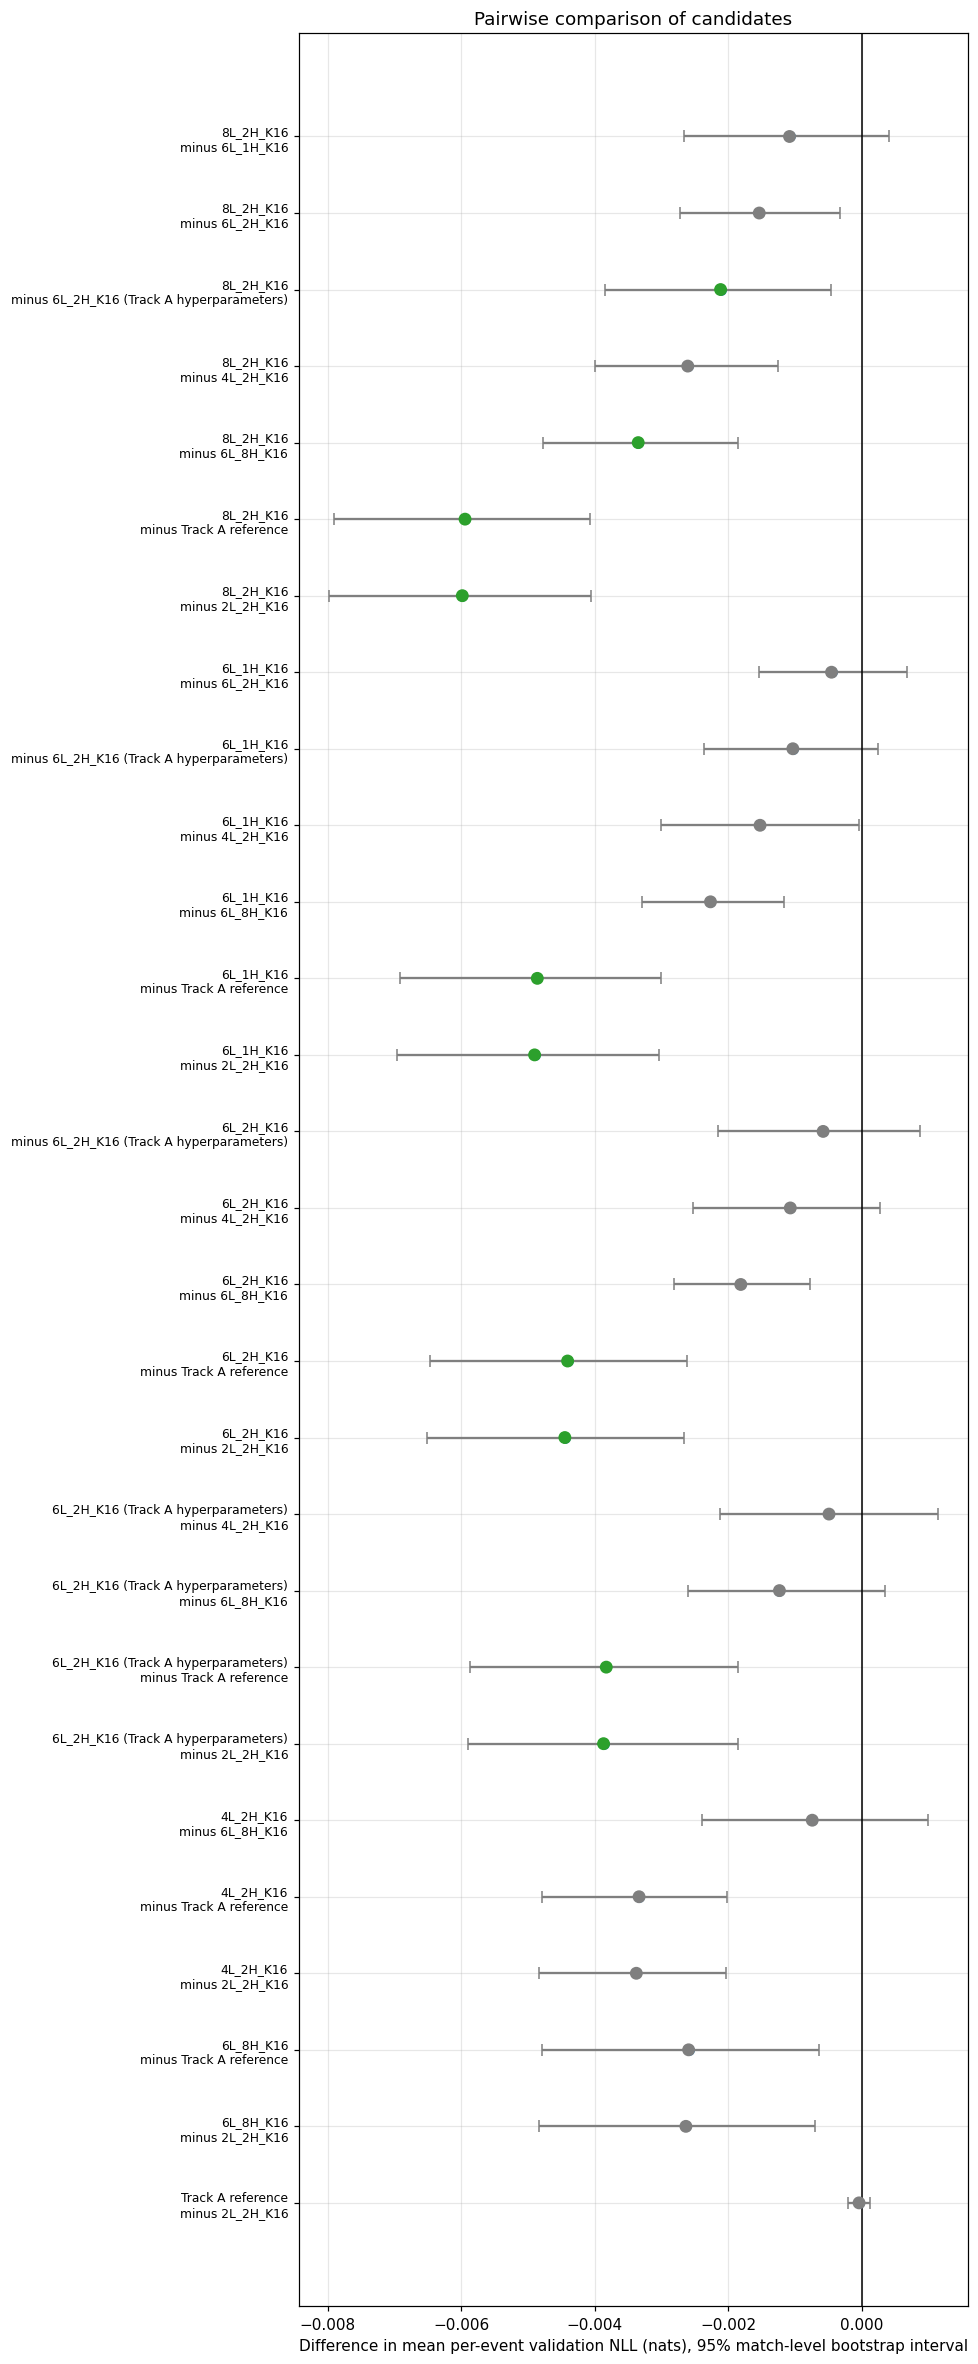

Pairs separated beyond noise: 10 of 28
  8L_2H_K16 beats 6L_2H_K16 (Track A hyperparameters) by 0.0021 nats [0.0005, 0.0038]
  8L_2H_K16 beats 6L_8H_K16 by 0.0033 nats [0.0018, 0.0048]
  8L_2H_K16 beats Track A reference by 0.0059 nats [0.0041, 0.0079]
  8L_2H_K16 beats 2L_2H_K16 by 0.0060 nats [0.0041, 0.0080]
  6L_1H_K16 beats Track A reference by 0.0049 nats [0.0030, 0.0069]
  6L_1H_K16 beats 2L_2H_K16 by 0.0049 nats [0.0030, 0.0070]
  6L_2H_K16 beats Track A reference by 0.0044 nats [0.0026, 0.0065]
  6L_2H_K16 beats 2L_2H_K16 by 0.0044 nats [0.0027, 0.0065]
  6L_2H_K16 (Track A hyperparameters) beats Track A reference by 0.0038 nats [0.0019, 0.0059]
  6L_2H_K16 (Track A hyperparameters) beats 2L_2H_K16 by 0.0039 nats [0.0019, 0.0059]


In [ ]:
fig, ax = plt.subplots(figsize=(9.0, 0.7 * len(pairwise) + 2.0))
labels = [f"{row['candidate_a']}\nminus {row['candidate_b']}" for _, row in pairwise.iterrows()]
positions = np.arange(len(pairwise))
errors = np.vstack([pairwise["difference_a_minus_b"] - pairwise["ci_low"],
                    pairwise["ci_high"] - pairwise["difference_a_minus_b"]])
colours = ["tab:green" if decided else "tab:grey" for decided in pairwise["a_better_beyond_noise"]]
ax.errorbar(pairwise["difference_a_minus_b"], positions, xerr=errors, fmt="o", capsize=4,
            ecolor="tab:grey", linestyle="none")
ax.scatter(pairwise["difference_a_minus_b"], positions, c=colours, s=55, zorder=3)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_yticks(positions)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Difference in mean per-event validation NLL (nats), 95% match-level bootstrap interval")
ax.set_title("Pairwise comparison of candidates")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_pairwise_intervals.png", bbox_inches="tight")
plt.show()

decided = pairwise[pairwise["a_better_beyond_noise"]]
print(f"Pairs separated beyond noise: {len(decided)} of {len(pairwise)}")
for _, row in decided.iterrows():
    print(f"  {row['candidate_a']} beats {row['candidate_b']} by {-row['difference_a_minus_b']:.4f} nats "
          f"[{-row['ci_high']:.4f}, {-row['ci_low']:.4f}]")
if len(decided) == 0:
    print("  none: no candidate is distinguishable from another under the Track A rule.")

**What are we looking at?** One row per pair. The point is the difference in mean per-event validation NLL (first minus second candidate); the bar is the 95% match-level bootstrap interval. Negative means the first candidate has the lower NLL. Green points satisfy both parts of the decision rule.

**RESULT.** 10 of 28 pairs are separated beyond noise. Each involves either a 2-layer candidate (the Track A reference or 2L_2H_K16) as the worse model, or the 8-layer model as the better one:

* 8L_2H_K16 beats the tuning check (by 0.0021), 6L_8H_K16 (0.0033), the Track A reference (0.0059) and 2L_2H_K16 (0.0060);
* 6L_1H_K16, 6L_2H_K16 and the tuning check each beat both 2-layer candidates (by 0.0038–0.0049).

**How to read it.** An interval crossing zero means the pair is undecided. A grey point whose interval is clear of zero is a pair where the bootstrap interval separates the candidates but the seeds overlap; the rule treats that as undecided too. Many comparisons are made and no correction for multiple comparisons is applied, so an interval that only just excludes zero is weak evidence on its own.

## 4a. Benchmark of the architectures at the tuned training setting

The pairwise table covers every pair. This section reads it from the side of the best benchmark candidate: the benchmark configuration with the lowest mean validation NLL, compared with every other candidate under the decision rule.

`compare_pair` applies the decision rule with the lower-NLL configuration as A. `describe` states the outcome in one of three forms:

* **beyond noise** — both criteria met;
* **inconclusive** — the bootstrap interval excludes zero but the seeds overlap;
* **no evidence for a difference** — the bootstrap interval includes zero.

All candidates are scored on the same validation events, so the bootstrap interval is a paired comparison.

In [ ]:
def compare_pair(label_a, runs_a, label_b, runs_b):
    # Track A decision rule, applied with the lower-NLL configuration as A.
    first = analysis.compare_conditions(runs_a, runs_b, targets, match_ids)
    if first["nll_a_mean"] <= first["nll_b_mean"]:
        result = first
        lower, higher = label_a, label_b
    else:
        result = analysis.compare_conditions(runs_b, runs_a, targets, match_ids)
        lower, higher = label_b, label_a
    result["lower"] = lower
    result["higher"] = higher
    # gap = NLL(higher) - NLL(lower) >= 0, with its interval in the same direction
    result["gap"] = -result["difference_a_minus_b"]
    result["gap_ci_low"] = -result["difference_ci_high"]
    result["gap_ci_high"] = -result["difference_ci_low"]
    return result


def describe(result):
    # Formal one-paragraph description of a pairwise comparison.
    text = (f"{result['lower']} had a lower mean validation NLL than {result['higher']} by {result['gap']:.4f} nats "
            f"(95% bootstrap CI of the gap {result['gap_ci_low']:.4f} to {result['gap_ci_high']:.4f}). ")
    if result["a_better_beyond_noise"]:
        text += "Both criteria of the decision rule were met, so the difference is treated as beyond noise."
    elif result["gap_ci_low"] > 0:
        text += ("The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the "
                 "decision rule; the comparison is inconclusive.")
    else:
        text += "The interval includes zero; the experiment does not provide evidence for a difference."
    return text


benchmark_table = stability_table[stability_table["role"] == "benchmark"].reset_index(drop=True)
BEST_CANDIDATE = str(benchmark_table.iloc[0]["candidate"])

best_versus_rows = []
for _, row in stability_table.iterrows():
    name = row["candidate"]
    seed_values = seed_table[seed_table["candidate"] == name].sort_values("seed")["val_nll"]
    record = {"candidate": name, "role": row["role"], "architecture": row["architecture"],
              "parameters": int(row["parameters"]), "learning_rate": row["learning_rate"],
              "weight_decay": row["weight_decay"], "seeds": int(row["n_seeds"]),
              "mean val NLL": row["val_nll_mean"], "NLL SD": row["val_nll_sd"],
              "per-seed val NLL": [round(value, 4) for value in seed_values]}
    if name == BEST_CANDIDATE:
        record.update({"is best": True, "status": "best benchmark configuration", "description": ""})
        best_versus_rows.append(record)
        continue
    result = compare_pair(BEST_CANDIDATE, candidate_run_dirs[BEST_CANDIDATE], name, candidate_run_dirs[name])
    best_is_lower = result["lower"] == BEST_CANDIDATE
    if result["a_better_beyond_noise"] and best_is_lower:
        status = "beaten beyond noise by the best"
    elif result["a_better_beyond_noise"]:
        status = "better than the best benchmark configuration beyond noise"
    elif result["gap_ci_low"] > 0:
        status = "within noise of the best (inconclusive)"
    else:
        status = "within noise of the best"
    record.update({"is best": False,
                   "best - candidate": result["gap"] if best_is_lower else -result["gap"],
                   "gap 95% CI": f"[{result['gap_ci_low']:.4f}, {result['gap_ci_high']:.4f}]",
                   "seeds separated": result["seeds_completely_separated"],
                   "beyond noise": result["a_better_beyond_noise"],
                   "status": status, "description": describe(result)})
    best_versus_rows.append(record)

best_versus = pd.DataFrame(best_versus_rows)
best_versus.to_csv(BEST_VERSUS_CSV, index=False)

print(f"Best benchmark configuration: {BEST_CANDIDATE}\n")
for _, row in best_versus[~best_versus["is best"]].iterrows():
    print(f"[{row['role']}] {row['description']}")
best_versus[["candidate", "role", "parameters", "seeds", "mean val NLL", "NLL SD", "per-seed val NLL",
             "best - candidate", "gap 95% CI", "seeds separated", "beyond noise", "status"]].round(4)

Best benchmark configuration: 8L_2H_K16

[benchmark] 8L_2H_K16 had a lower mean validation NLL than 6L_1H_K16 by 0.0011 nats (95% bootstrap CI of the gap -0.0004 to 0.0027). The interval includes zero; the experiment does not provide evidence for a difference.
[benchmark] 8L_2H_K16 had a lower mean validation NLL than 6L_2H_K16 by 0.0015 nats (95% bootstrap CI of the gap 0.0003 to 0.0027). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.
[tuning check] 8L_2H_K16 had a lower mean validation NLL than 6L_2H_K16 (Track A hyperparameters) by 0.0021 nats (95% bootstrap CI of the gap 0.0005 to 0.0038). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
[benchmark] 8L_2H_K16 had a lower mean validation NLL than 4L_2H_K16 by 0.0026 nats (95% bootstrap CI of the gap 0.0013 to 0.0040). The interval excludes zero, but the per-seed results overlapped, so the dif

,candidate,role,parameters,seeds,mean val NLL,NLL SD,per-seed val NLL,best - candidate,gap 95% CI,seeds separated,beyond noise,status
0,8L_2H_K16,benchmark,1704207,5,0.9010,0.0005,"[0.9007, 0.9009, 0.9005, 0.9017, 0.9011]",NaN,NaN,NaN,NaN,best benchmark configuration
1,6L_1H_K16,benchmark,1307663,5,0.9021,0.0015,"[0.9037, 0.9025, 0.902, 0.9024, 0.8997]",0.0011,"[-0.0004, 0.0027]",False,False,within noise of the best
2,6L_2H_K16,benchmark,1307663,5,0.9025,0.0015,"[0.9044, 0.9026, 0.9028, 0.9027, 0.9001]",0.0015,"[0.0003, 0.0027]",False,False,within noise of the best (inconclusive)
3,6L_2H_K16 (Track A hyperparameters),tuning check,1307663,5,0.9031,0.0010,"[0.9045, 0.9031, 0.9026, 0.9035, 0.9018]",0.0021,"[0.0005, 0.0038]",True,True,beaten beyond noise by the best
4,4L_2H_K16,benchmark,911119,5,0.9036,0.0017,"[0.9055, 0.9035, 0.9022, 0.9051, 0.9016]",0.0026,"[0.0013, 0.0040]",False,False,within noise of the best (inconclusive)
5,6L_8H_K16,benchmark,1307663,5,0.9043,0.0017,"[0.9072, 0.9033, 0.904, 0.904, 0.9032]",0.0033,"[0.0018, 0.0048]",True,True,beaten beyond noise by the best
6,Track A reference,reference,514575,5,0.9069,0.0018,"[0.9064, 0.9067, 0.9063, 0.91, 0.9052]",0.0059,"[0.0041, 0.0079]",True,True,beaten beyond noise by the best
7,2L_2H_K16,benchmark,514575,5,0.9070,0.0020,"[0.9066, 0.9067, 0.9064, 0.9103, 0.9049]",0.0060,"[0.0041, 0.0080]",True,True,beaten beyond noise by the best


**RESULT.** The best benchmark configuration is **8L_2H_K16** (0.9010). Against it:

| Candidate | Gap (95% CI) | Outcome |
|---|---|---|
| 6L_1H_K16 | 0.0011 [−0.0004, 0.0027] | no evidence for a difference |
| 6L_2H_K16 | 0.0015 [0.0003, 0.0027] | inconclusive (seeds overlap) |
| 4L_2H_K16 | 0.0026 [0.0013, 0.0040] | inconclusive (seeds overlap) |
| 6L_8H_K16 | 0.0033 [0.0018, 0.0048] | beyond noise |
| 2L_2H_K16 | 0.0060 [0.0041, 0.0080] | beyond noise |
| tuning check (6L_2H, wd 0.1) | 0.0021 [0.0005, 0.0038] | beyond noise |
| Track A reference (2L_2H, wd 0.1) | 0.0059 [0.0041, 0.0079] | beyond noise |

**INTERPRETATION.** Among the benchmark candidates, three are within noise of the best: 6L_1H_K16, 6L_2H_K16 and 4L_2H_K16. Two are beaten beyond noise: 6L_8H_K16 and 2L_2H_K16. For 6L_2H_K16 and 4L_2H_K16 the bootstrap interval alone would separate them from the best; they are within noise because their seeds overlap with those of 8L_2H_K16.

The reference and tuning-check rows are included for comparison only; they differ from the benchmark candidates in training setting, so they are not architecture comparisons.

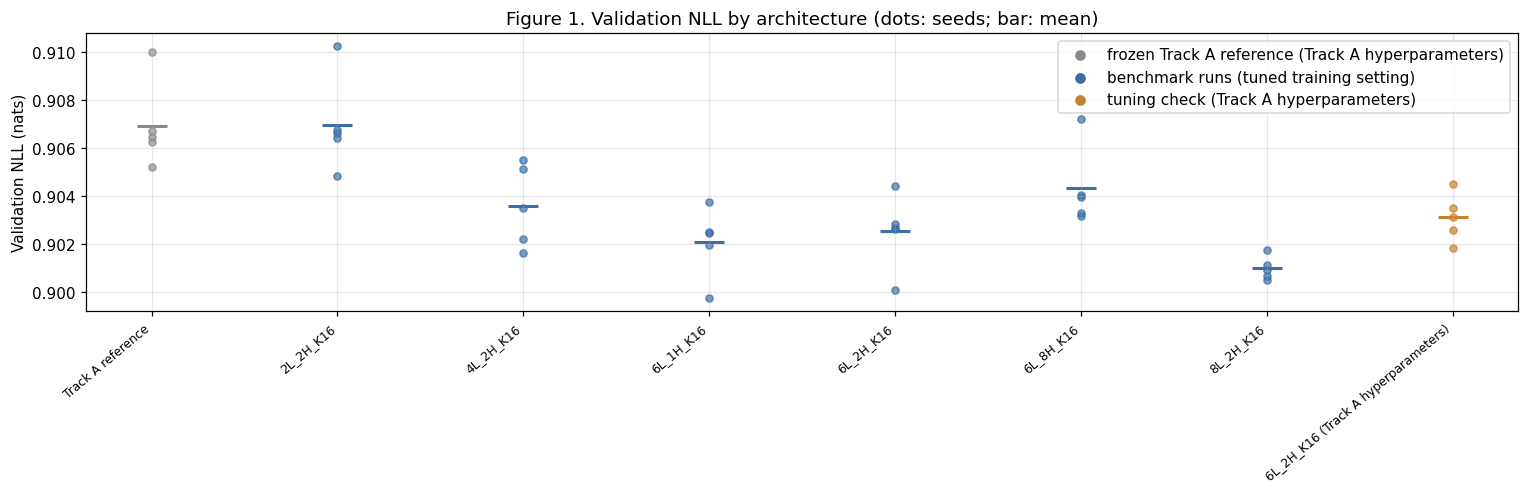

In [ ]:
ROLE_COLOURS = {"reference": "#8a8a8a", "benchmark": "#3b6ea5", "tuning check": "#c9822b"}
ROLE_LEGEND = {"reference": "frozen Track A reference (Track A hyperparameters)",
               "benchmark": "benchmark runs (tuned training setting)",
               "tuning check": "tuning check (Track A hyperparameters)"}


def plot_metric_by_configuration(metric, ylabel, title, file_name):
    # One point per seed and the configuration mean, for every candidate of the benchmark.
    plot_rows = stability_table.copy()
    plot_rows["role order"] = plot_rows["role"].map({"reference": 0, "benchmark": 1, "tuning check": 2})
    plot_rows["head-position units"] = plot_rows["n_layers"] * plot_rows["n_heads"] * plot_rows["context_length"]
    plot_rows = plot_rows.sort_values(["role order", "parameters", "head-position units"]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 4.6))
    for position, row in plot_rows.iterrows():
        colour = ROLE_COLOURS[row["role"]]
        seed_values = seed_table[seed_table["candidate"] == row["candidate"]][metric].to_numpy()
        ax.scatter(np.full(len(seed_values), position), seed_values, color=colour, s=22, alpha=0.7)
        ax.scatter([position], [np.mean(seed_values)], color=colour, marker="_", s=400, linewidths=2)
    ax.set_xticks(range(len(plot_rows)))
    ax.set_xticklabels(plot_rows["candidate"], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    for role in ["reference", "benchmark", "tuning check"]:
        if role in set(plot_rows["role"]):
            ax.scatter([], [], color=ROLE_COLOURS[role], label=ROLE_LEGEND[role])
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / file_name, bbox_inches="tight", dpi=300)
    plt.show()


plot_metric_by_configuration("val_nll", "Validation NLL (nats)",
                             "Figure 1. Validation NLL by architecture (dots: seeds; bar: mean)",
                             "11_fig1_nll_by_architecture.png")

**What are we looking at? (Figure 1)** Validation NLL of every seed (dots) and the mean (horizontal bar) for each candidate: the frozen Track A reference (grey), the shortlisted architectures at the tuned setting (blue), and the tuning check (orange). Seeds 10–14 throughout. Lower is better.

**What it shows.** The size of the differences between configurations next to the spread between seeds of the same configuration, which is exactly the comparison the decision rule formalises. The 2-layer candidates lie above the rest; the 4-, 6- and 8-layer candidates overlap.

**What we cannot conclude.** The figure does not show that all candidates are scored on the same events, so it does not replace the paired bootstrap comparison of Section 4a.

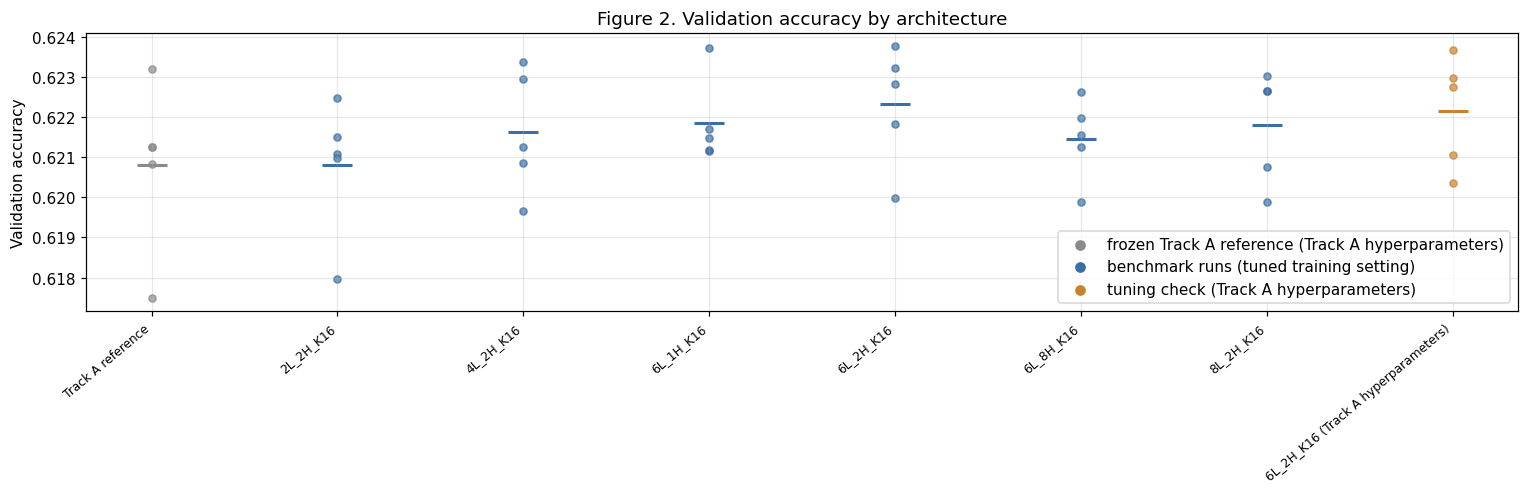

In [ ]:
plot_metric_by_configuration("val_accuracy", "Validation accuracy", "Figure 2. Validation accuracy by architecture",
                             "11_fig2_accuracy_by_architecture.png")

**Figure 2.** Validation accuracy of every seed (dots) and the mean (horizontal bar), in the same layout as Figure 1. Higher is better. Means range from 0.6208 (the two 2-layer candidates) to 0.6223 (6L_2H_K16); the seed-to-seed spread within candidates is of the same size. Accuracy is a secondary metric: it scores only the top-ranked class and does not enter the selection, which uses validation NLL.

## 4b. Depth at the tuned training setting

**Why this comparison.** An earlier 4-layer benchmark of this model family (trained at the Track A setting) chose 4L_2H_K16 among 4-layer configurations, and the capacity sweep placed 6L_2H_K16 first on two screening seeds. Those results came from different seed sets and, for the 6-layer model, a different weight decay, so they do not show how the two compare. The benchmark candidates share the training setting and the seeds, so the comparison can be made here directly.

**Control.** 2 heads, K = 16, d_model 128, d_ff 512, tuned training setting, seeds 10–14. Only the number of layers changes. Each depth is compared with the next deeper one under the decision rule; the 4-against-6-layer comparison is printed in full below the table.

In [ ]:
depth_series = benchmark_table[(benchmark_table["n_heads"] == 2) & (benchmark_table["context_length"] == 16)
                               & (benchmark_table["d_model"] == BASE_D_MODEL)
                               & (benchmark_table["d_ff"] == BASE_D_FF)].sort_values("n_layers")
depth_rows = []
for position in range(1, len(depth_series)):
    shallow = depth_series.iloc[position - 1]
    deep = depth_series.iloc[position]
    result = compare_pair(shallow["candidate"], candidate_run_dirs[shallow["candidate"]],
                          deep["candidate"], candidate_run_dirs[deep["candidate"]])
    depth_rows.append({"comparison": f"{shallow['candidate']} vs {deep['candidate']}",
                       "lower NLL": result["lower"], "gap (higher - lower NLL)": result["gap"],
                       "95% CI of gap": f"[{result['gap_ci_low']:.4f}, {result['gap_ci_high']:.4f}]",
                       "seeds separated": result["seeds_completely_separated"],
                       "beyond noise": result["a_better_beyond_noise"],
                       "description": describe(result)})
depth_table = pd.DataFrame(depth_rows)
depth_table.to_csv(DEPTH_CSV, index=False)
for text in depth_table["description"]:
    print(text)
depth_table.drop(columns="description").round(4)

4L_2H_K16 had a lower mean validation NLL than 2L_2H_K16 by 0.0034 nats (95% bootstrap CI of the gap 0.0020 to 0.0048). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.
6L_2H_K16 had a lower mean validation NLL than 4L_2H_K16 by 0.0011 nats (95% bootstrap CI of the gap -0.0003 to 0.0025). The interval includes zero; the experiment does not provide evidence for a difference.
8L_2H_K16 had a lower mean validation NLL than 6L_2H_K16 by 0.0015 nats (95% bootstrap CI of the gap 0.0003 to 0.0027). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.


,comparison,lower NLL,gap (higher - lower NLL),95% CI of gap,seeds separated,beyond noise
0,2L_2H_K16 vs 4L_2H_K16,4L_2H_K16,0.0034,"[0.0020, 0.0048]",False,False
1,4L_2H_K16 vs 6L_2H_K16,6L_2H_K16,0.0011,"[-0.0003, 0.0025]",False,False
2,6L_2H_K16 vs 8L_2H_K16,8L_2H_K16,0.0015,"[0.0003, 0.0027]",False,False


In [ ]:
four_layer = benchmark_table[(benchmark_table["n_layers"] == 4) & (benchmark_table["n_heads"] == 2)
                             & (benchmark_table["context_length"] == 16)]
six_layer = benchmark_table[(benchmark_table["n_layers"] == 6) & (benchmark_table["n_heads"] == 2)
                            & (benchmark_table["context_length"] == 16)]
if len(four_layer) == 0 or len(six_layer) == 0:
    four_versus_six = None
    print("4L_2H_K16 or 6L_2H_K16 is not among the benchmark candidates; the comparison is not available.")
else:
    four_name = str(four_layer.iloc[0]["candidate"])
    six_name = str(six_layer.iloc[0]["candidate"])
    four_versus_six = compare_pair(four_name, candidate_run_dirs[four_name], six_name, candidate_run_dirs[six_name])
    for name in [four_name, six_name]:
        values = seed_table[seed_table["candidate"] == name].sort_values("seed")["val_nll"]
        print(f"{name}: mean {values.mean():.4f} | SD {values.std(ddof=1):.4f} | "
              f"seeds {[round(value, 4) for value in values]}")
    print()
    print(describe(four_versus_six))
    print(f"Interval excludes zero: {four_versus_six['gap_ci_low'] > 0} | "
          f"all seeds of {four_versus_six['lower']} below all seeds of {four_versus_six['higher']}: "
          f"{four_versus_six['seeds_completely_separated']}")

4L_2H_K16: mean 0.9036 | SD 0.0017 | seeds [0.9055, 0.9035, 0.9022, 0.9051, 0.9016]
6L_2H_K16: mean 0.9025 | SD 0.0015 | seeds [0.9044, 0.9026, 0.9028, 0.9027, 0.9001]

6L_2H_K16 had a lower mean validation NLL than 4L_2H_K16 by 0.0011 nats (95% bootstrap CI of the gap -0.0003 to 0.0025). The interval includes zero; the experiment does not provide evidence for a difference.
Interval excludes zero: False | all seeds of 6L_2H_K16 below all seeds of 4L_2H_K16: False


**RESULT.**

* **2 → 4 layers:** 4L_2H_K16 is lower by 0.0034 [0.0020, 0.0048]; the interval excludes zero but the seeds overlap — inconclusive.
* **4 → 6 layers:** 6L_2H_K16 is lower by 0.0011 [−0.0003, 0.0025] — no evidence for a difference. Seeds: 4 layers 0.9016–0.9055, 6 layers 0.9001–0.9044.
* **6 → 8 layers:** 8L_2H_K16 is lower by 0.0015 [0.0003, 0.0027] — inconclusive.

**INTERPRETATION.** No single depth step meets the decision rule at five seeds. Each step lowers mean NLL, and two of the three bootstrap intervals exclude zero, but the seed distributions of neighbouring depths overlap. Over two steps the picture is mixed: 6L_2H_K16 and 8L_2H_K16 are both better than 2L_2H_K16 beyond noise, but 8L_2H_K16 against 4L_2H_K16 is not (Section 4a).

## 4c. Tuning check

The benchmark 6L_2H_K16 (weight decay 0.01) and the tuning check (weight decay 0.1) differ only in weight decay. Their comparison states whether the tuned setting improves on the Track A setting for this architecture with five seeds; the hyperparameter search made the same comparison with two seeds and found no difference beyond noise (−0.0006 [−0.0013, +0.0001]).

In [ ]:
check_rows = stability_table[stability_table["role"] == "tuning check"]
if len(check_rows) == 0:
    tuning_check = None
    print("No tuning check: the tuned setting coincides with the Track A training hyperparameters.")
else:
    check_name = str(check_rows.iloc[0]["candidate"])
    tuned_name = str(benchmark_table[benchmark_table["architecture"] == check_rows.iloc[0]["architecture"]]
                     .iloc[0]["candidate"])
    tuning_check = compare_pair(f"{tuned_name} (tuned)", candidate_run_dirs[tuned_name],
                                check_name, candidate_run_dirs[check_name])
    print(describe(tuning_check))

6L_2H_K16 (tuned) had a lower mean validation NLL than 6L_2H_K16 (Track A hyperparameters) by 0.0006 nats (95% bootstrap CI of the gap -0.0009 to 0.0021). The interval includes zero; the experiment does not provide evidence for a difference.


**RESULT.** 6L_2H_K16 at weight decay 0.01 is lower than at weight decay 0.1 by 0.0006 nats, 95% bootstrap interval [−0.0009, 0.0021]. The interval includes zero: no evidence for a difference.

**INTERPRETATION.** With five seeds, the tuned weight decay (0.01) and the Track A weight decay (0.1) cannot be distinguished for this architecture — the same conclusion as with two seeds. The two 2-layer candidates, which also differ only in weight decay, have means of 0.9069 and 0.9070. The tuned setting is therefore a choice between settings that perform alike on validation, not a measured improvement.

## 5. Stability of calibration and of the stopping point

Validation NLL is the selection metric, but a configuration that reaches its best NLL at an unpredictable epoch, or whose calibration varies widely between seeds, is less useful than its mean suggests. The two panels below report those two properties.

/tmp/ipykernel_2248/606893414.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(ece_groups, labels=order, widths=0.5)


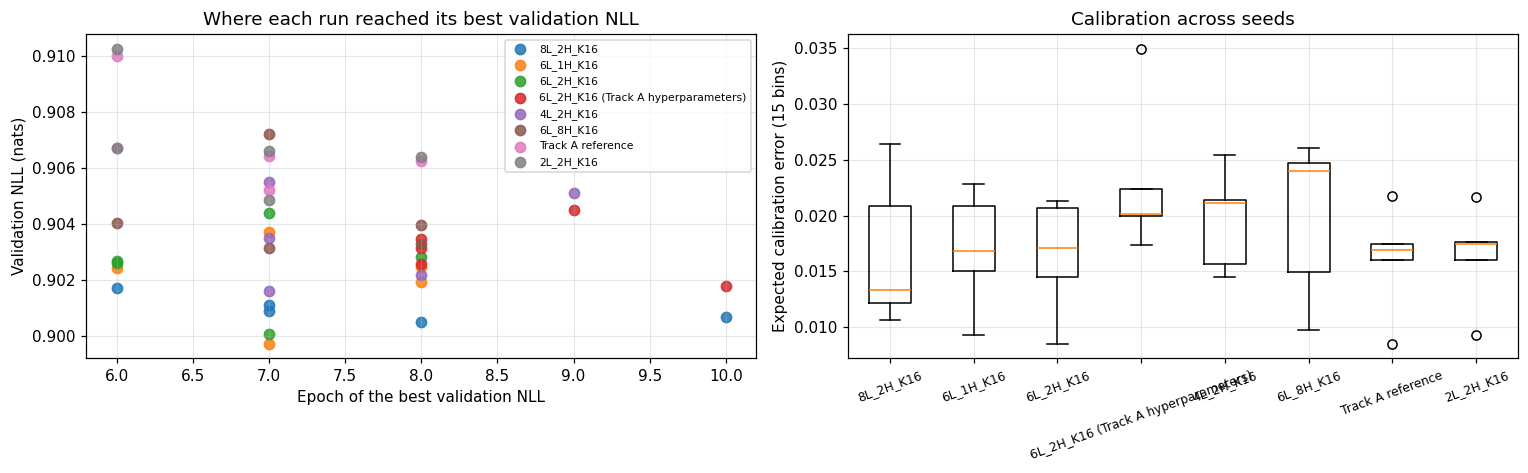

                          candidate  best_epoch_min  best_epoch_max  val_ece_mean  val_ece_sd  val_macro_f1_mean  val_macro_f1_sd
                          8L_2H_K16               6              10        0.0167      0.0067             0.5618           0.0021
                          6L_1H_K16               6               8        0.0170      0.0053             0.5577           0.0047
                          6L_2H_K16               6               8        0.0164      0.0052             0.5601           0.0024
6L_2H_K16 (Track A hyperparameters)               8              10        0.0230      0.0069             0.5593           0.0081
                          4L_2H_K16               7               9        0.0196      0.0045             0.5590           0.0033
                          6L_8H_K16               6               8        0.0199      0.0072             0.5600           0.0069
                  Track A reference               6               8        0.0161      0.0

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for name in order:
    subset = seed_table[seed_table["candidate"] == name]
    axes[0].scatter(subset["best_epoch"], subset["val_nll"], s=45, label=name, alpha=0.85)
axes[0].set_xlabel("Epoch of the best validation NLL")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("Where each run reached its best validation NLL")
axes[0].legend(fontsize=7)

ece_groups = [seed_table[seed_table["candidate"] == name]["val_ece"].to_numpy() for name in order]
axes[1].boxplot(ece_groups, labels=order, widths=0.5)
axes[1].set_ylabel("Expected calibration error (15 bins)")
axes[1].set_title("Calibration across seeds")
axes[1].tick_params(axis="x", labelrotation=20, labelsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_stability_diagnostics.png", bbox_inches="tight")
plt.show()

print(stability_table[["candidate", "best_epoch_min", "best_epoch_max", "val_ece_mean", "val_ece_sd",
                       "val_macro_f1_mean", "val_macro_f1_sd"]].round(4).to_string(index=False))

**What are we looking at?** Left: each run placed at the epoch where it reached its lowest validation NLL, against that NLL, coloured by candidate. Right: the distribution of expected calibration error (15 bins) across the five seeds of each candidate.

**RESULT.** Best epochs lie between 6 and 10 for every candidate (6–8 for most; 6–10 for 8L_2H_K16, 7–9 for 4L_2H_K16, 8–10 for the tuning check). Mean ECE ranges from 0.0161 (Track A reference) to 0.0230 (tuning check); the seed SD of ECE is 0.0045–0.0072, a large fraction of the mean in every case.

**INTERPRETATION.** Every candidate stops within a narrow band of epochs, so none of the means depends strongly on the early-stopping rule. Calibration is less stable: the ECE of a single trained model cannot be predicted closely from the candidate's mean. This matters because only one checkpoint (the median-seed run) is released after final training, not an average.

## 6. What this notebook establishes

The report below records the best benchmark configuration, the candidates within noise of it and those beaten beyond noise, and the **smallest benchmark configuration that the best one does not beat beyond noise**.


**RESULT.** Order: 2L_2H_K16, 4L_2H_K16, 6L_1H_K16, 6L_2H_K16, 6L_8H_K16, 8L_2H_K16. The best (8L_2H_K16) beats 2L_2H_K16 beyond noise, but not 4L_2H_K16 (gap 0.0026 [0.0013, 0.0040], seeds not separated). **The smallest candidate within noise of the best is 4L_2H_K16** (911,119 parameters).

In [ ]:
size_order = benchmark_table.copy()
size_order["head-position units"] = size_order["n_layers"] * size_order["n_heads"] * size_order["context_length"]
size_order = size_order.sort_values(["parameters", "head-position units", "val_nll_mean"])
ordered_candidates = [(row["candidate"], candidate_run_dirs[row["candidate"]]) for _, row in size_order.iterrows()]
chosen_by_rule, smallest_table = analysis.smallest_within_noise(ordered_candidates, targets, match_ids)
print("Order from smallest to largest (parameters, then head-position units):", list(size_order["candidate"]))
print("Smallest candidate the best one does not beat beyond noise:", chosen_by_rule)
print()
print(smallest_table.to_string())

Order from smallest to largest (parameters, then head-position units): ['2L_2H_K16', '4L_2H_K16', '6L_1H_K16', '6L_2H_K16', '6L_8H_K16', '8L_2H_K16']
Smallest candidate the best one does not beat beyond noise: 4L_2H_K16

           mean val NLL  is best  best beats it beyond noise       best - candidate (CI) seeds separated
candidate                                                                                               
2L_2H_K16        0.9070    False                        True  -0.0060 [-0.0080, -0.0041]            True
4L_2H_K16        0.9036    False                       False  -0.0026 [-0.0040, -0.0013]           False
6L_1H_K16        0.9021    False                       False  -0.0011 [-0.0027, +0.0004]           False
6L_2H_K16        0.9025    False                       False  -0.0015 [-0.0027, -0.0003]           False
6L_8H_K16        0.9043    False                        True  -0.0033 [-0.0048, -0.0018]            True
8L_2H_K16        0.9010     True            

In [ ]:
best_candidate = benchmark_table.iloc[0]
track_a_rows = stability_table[stability_table["role"] == "reference"]
if len(track_a_rows) == 0:
    track_a_rows = stability_table[stability_table["candidate"] == "Track A reference"]
benchmark_rows = best_versus[best_versus["role"] == "benchmark"]

stability_report = {
    "seeds": STABILITY_SEEDS,
    "seed_count_origin": "matches the Track A final-training protocol; provisional as a budget",
    "selected_training": candidate_record["selected_training"],
    "candidates": stability_table.to_dict(orient="records"),
    "pairwise": pairwise.to_dict(orient="records"),
    "best_by_mean_val_nll": str(best_candidate["candidate"]),
    "best_mean_val_nll": float(best_candidate["val_nll_mean"]),
    "best_val_nll_sd": float(best_candidate["val_nll_sd"]),
    "within_noise_of_best": list(benchmark_rows[benchmark_rows["status"].str.startswith("within noise")]["candidate"]),
    "beaten_beyond_noise_by_best": list(benchmark_rows[benchmark_rows["status"] == "beaten beyond noise by the best"]
                                        ["candidate"]),
    "smallest_within_noise_of_best": str(chosen_by_rule),
    "size_order": list(size_order["candidate"]),
    "four_versus_six_layers": (None if four_versus_six is None else
                               {key: four_versus_six[key] for key in ["lower", "higher", "gap", "gap_ci_low",
                                                                      "gap_ci_high", "seeds_completely_separated",
                                                                      "a_better_beyond_noise"]}),
    "tuning_check": (None if tuning_check is None else
                     {key: tuning_check[key] for key in ["lower", "higher", "gap", "gap_ci_low", "gap_ci_high",
                                                         "seeds_completely_separated", "a_better_beyond_noise"]}),
    "pairs_separated_beyond_noise": int(len(decided)),
    "track_a_reference_mean_val_nll": (float(track_a_rows.iloc[0]["val_nll_mean"]) if len(track_a_rows) else None),
    "test_split_touched": False,
}
training.save_json(STABILITY_REPORT_JSON, stability_report)

print(f"Lowest mean validation NLL among the benchmark candidates: {best_candidate['candidate']} at "
      f"{best_candidate['val_nll_mean']:.4f} (SD {best_candidate['val_nll_sd']:.4f}, "
      f"range {best_candidate['val_nll_range']:.4f})")
if len(track_a_rows):
    gap = track_a_rows.iloc[0]["val_nll_mean"] - best_candidate["val_nll_mean"]
    print(f"Track A reference: {track_a_rows.iloc[0]['val_nll_mean']:.4f} "
          f"(SD {track_a_rows.iloc[0]['val_nll_sd']:.4f}); gap {gap:+.4f} nats")
print("Within noise of the best:", stability_report["within_noise_of_best"])
print("Beaten beyond noise by the best:", stability_report["beaten_beyond_noise_by_best"])
print(f"Smallest candidate within noise of the best: {chosen_by_rule}")
print("\nModel selection is based on validation data only; test data were not used.")
print(f"Report written to {STABILITY_REPORT_JSON}")

Lowest mean validation NLL among the benchmark candidates: 8L_2H_K16 at 0.9010 (SD 0.0005, range 0.0012)
Track A reference: 0.9069 (SD 0.0018); gap +0.0059 nats
Within noise of the best: ['6L_1H_K16', '6L_2H_K16', '4L_2H_K16']
Beaten beyond noise by the best: ['6L_8H_K16', '2L_2H_K16']
Smallest candidate within noise of the best: 4L_2H_K16

Model selection is based on validation data only; test data were not used.
Report written to /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/results/11_stability_report.json


## 7. Summary

| Item | Result |
|---|---|
| Runs | 8 candidates × seeds 10–14 = 40 |
| Best benchmark configuration | 8L_2H_K16, mean validation NLL 0.9010 (seed SD 0.0005, range 0.0012) |
| Within noise of the best | 6L_1H_K16, 6L_2H_K16, 4L_2H_K16 |
| Beaten beyond noise by the best | 6L_8H_K16, 2L_2H_K16 (also the reference and the tuning check) |
| Smallest within noise of the best | 4L_2H_K16 |
| Track A reference | 0.9069 (SD 0.0018); 0.0059 above the best, beyond noise |
| Depth steps (2→4, 4→6, 6→8) | none beyond noise individually |
| Tuning check (weight decay 0.01 vs 0.1, 6L_2H_K16) | 0.0006 [−0.0009, 0.0021]: no evidence for a difference |
| Test split | not accessed; no Track A file written |

The file `results/11_stability_report.json` holds the candidate summaries, the pairwise comparisons, the best benchmark configuration, the candidates within noise of it and the smallest such candidate. These are the inputs of the final model selection, which is based on validation data only.
